In [ ]:
import pandas as pd
import sys
import os
sys.path.append('/home/brush')
import statools
import mltools
import numpy as np
from sklearn.preprocessing import StandardScaler
import json
from sklearn.linear_model import LassoCV
from tqdm import tqdm
import argparse
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

ROOT = "/home/ANGPTL3/metascore/"

COV_FILE = ROOT + 'cov.pickle'
PROT_FILE = ROOT + 'ANGPTL3.pickle'
NMR_FILE = ROOT + 'nomiss-NMR251.pickle'
KEEP_FILE = '/home/ANGPTL3/nodrug10_ANGPTL3.eid'
COVLIST = ['sex', 'age', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10']


def load_data():
    cov = pd.read_pickle(COV_FILE)
    cov = cov[['eid'] + COVLIST]
    prot = pd.read_pickle(PROT_FILE)
    prot['ANGPTL3'] = (prot['ANGPTL3'] - prot['ANGPTL3'].mean()) / prot['ANGPTL3'].std()
    prot = prot.dropna().reset_index(drop=True)
    nmr = pd.read_pickle(NMR_FILE)
    
    train_idx = set(prot['eid']).intersection(set(nmr['eid']))
    train_nmr = nmr[nmr['eid'].isin(train_idx)].reset_index(drop=True)
    train_prot = prot[prot['eid'].isin(train_idx)].reset_index(drop=True)
    
    test_idx = set(nmr['eid']) - set(train_idx)
    test_nmr = nmr[nmr['eid'].isin(test_idx)].reset_index(drop=True)
    
    assert train_nmr.shape[0] + test_nmr.shape[0] == nmr.shape[0], "Error in spliting NMR data"
    # assert cov['eid'].nunique() == cov.shape[0], "Error in cov data: duplicated eids"
    assert train_prot['eid'].nunique() == train_prot.shape[0], "Error in prot data: duplicated eids"
    assert train_nmr['eid'].nunique() == train_nmr.shape[0], "Error in nmr data: duplicated eids"
    assert test_nmr['eid'].nunique() == test_nmr.shape[0], "Error in nmr data: duplicated eids"
    
    return pd.merge(train_prot, train_nmr, on='eid'), test_nmr, prot, cov


train, test, truth_prot, cov = load_data()

keep_eid = pd.read_csv(KEEP_FILE, header=None)[0].tolist()
train = train[train['eid'].isin(keep_eid)].reset_index(drop=True)

train = train.dropna().drop_duplicates(['eid']).reset_index(drop=True)
test = test.dropna().drop_duplicates(['eid']).reset_index(drop=True)
train.shape, test.shape

((9536, 253), (94930, 252))

In [4]:
test['Free_cholesterol_in_large_LDL'].describe()

count    94930.000000
mean         0.291834
std          0.076492
min          0.000000
25%          0.239720
50%          0.288550
75%          0.340390
max          0.898950
Name: Free_cholesterol_in_large_LDL, dtype: float64

In [2]:
train = pd.merge(train, cov, on='eid').reset_index(drop=True)
test = pd.merge(test, cov, on='eid').reset_index(drop=True)

# val_idx, train_idx = mltools.train_val_split(train['eid'])
# train_df, val_df = train[train['eid'].isin(train_idx)], train[train['eid'].isin(val_idx)]

print(train.shape, test.shape)
# best_alpha = 0.0002989228250219267
# best_alpha = 0.002900112120075828
best_alpha = 0.006697810659409802
train, scaler = mltools.scale_standard(train, rm_cols=['eid', 'ANGPTL3']+COVLIST)
train = train.dropna().reset_index(drop=True)
print(train.shape)

model = LassoCV(cv=5, alphas=[best_alpha], random_state=0)
model.fit(train.drop(['eid', 'ANGPTL3'], axis=1), train['ANGPTL3'])

(9536, 265) (94930, 264)
(9511, 265)


,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"n_alphas n_alphas: int, default=100Number of alphas along the regularization path... deprecated:: 1.7 `n_alphas` was deprecated in 1.7 and will be removed in 1.9. Use `alphas` instead.",'deprecated'
,"alphas alphas: array-like or int, default=NoneValues of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`... deprecated:: 1.7 `alphas=None` was deprecated in 1.7 and will be removed in 1.9, at which point the default value will be set to 100.",[0.006697810659409802]
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [3]:
train.columns.tolist()[-5:]

['PC6', 'PC7', 'PC8', 'PC9', 'PC10']

In [4]:
'CAD' in train.columns

False

In [5]:
weights = zip(model.feature_names_in_, model.coef_)
weights = pd.DataFrame(weights, columns=['feature', 'weight'])
keep_meta = weights[weights['weight'] != 0]['feature'].tolist()
keep_meta = [meta for meta in keep_meta if meta not in COVLIST]
print(f"bias: {model.intercept_}, non-zero weights: {weights[weights['weight'] != 0].shape[0]}\n"
      f"non-zero features: {keep_meta[:5]}...")
weights.head()

bias: -1.1033095167457663, non-zero weights: 51
non-zero features: ['Isoleucine', 'Glycine', 'Glycoprotein_acetyls', 'Average_diameter_for_HDL_particles', 'Tyrosine']...


,feature,weight
0,Total_esterified_cholesterol,0.000000
1,Phospholipids_to_total_lipids_ratio_in_small_HDL,0.000000
2,Isoleucine,-0.001669
3,Cholesteryl_esters_in_very_large_HDL,0.000000
4,Clinical_LDL_cholesterol,0.000000


# check up-down stream features

In [6]:
train = train[['eid', 'ANGPTL3'] + keep_meta + COVLIST]
train.shape

(9511, 56)

In [ ]:
import statools as statistics
cov = pd.read_csv('/home/ANGPTL3/noProt_UKB_drug.txt.gz', sep='\t', compression='gzip')
cov = cov[['eid', 'incident', 'prevalence', 'survive_time']]
cov = cov.drop_duplicates(['eid']).reset_index(drop=True)

df = pd.merge(train, cov, on='eid').reset_index(drop=True)
df = df[df['prevalence'] == 0].reset_index(drop=True)
print(df.shape)
print(df['incident'].value_counts().to_dict())

(9394, 59)
{0.0: 8701, 1.0: 693}


In [ ]:
# A is ANGPTL3, M is meta, Y is significant, N is not significant
AYMY, AYMN, ANMY, ANMN, ERR = [], [], [], [], {}
SAYMY, SAYMN, SANMY, SANMN = [], [], [], []
SSAYMY, SSAYMN, SSANMY, SSANMN = [], [], [], []

In [9]:
from tqdm import tqdm
sv_info = {'omic':[], 'beta':[], 'se':[], 'p':[], 'cond_beta':[], 'cond_se':[], 'cond_p':[]}
for meta in tqdm(keep_meta):
    try:
        res = statistics.surv_model(df, ['survive_time', 'incident'], ['ANGPTL3', meta], COVLIST, verbose=False, onehot_verbose=False)
        res = res.reset_index()
        sv_info['omic'].append(meta)
        sv_info['cond_beta'].append(res.loc[res['covariate'] == meta, 'coef'].values[0])
        sv_info['cond_se'].append(res.loc[res['covariate'] == meta, 'se(coef)'].values[0])
        sv_info['cond_p'].append(res.loc[res['covariate'] == meta, 'p'].values[0])
        pa = res.loc[res['covariate'] == 'ANGPTL3', 'p'].values[0]
        pm = res.loc[res['covariate'] == meta, 'p'].values[0]
        if pa < 0.05 and pm < 0.05:
            AYMY.append(meta)
        elif pa < 0.05 <= pm:
            AYMN.append(meta)
        elif pa >= 0.05 > pm:
            ANMY.append(meta)
        else:
            ANMN.append(meta)
    except Exception as e:
        ERR[meta] = str(e)

  2%|▏         | 1/42 [00:00<00:12,  3.22it/s]

0.7014069397547745


  5%|▍         | 2/42 [00:00<00:11,  3.45it/s]

0.705050282754267


  7%|▋         | 3/42 [00:00<00:11,  3.46it/s]

0.7151977551196125


 10%|▉         | 4/42 [00:01<00:10,  3.57it/s]

0.7073723550067834


 12%|█▏        | 5/42 [00:01<00:10,  3.58it/s]

0.7018698582389018


 14%|█▍        | 6/42 [00:01<00:10,  3.47it/s]

0.7076672266013406


 17%|█▋        | 7/42 [00:01<00:09,  3.53it/s]

0.7020512026073696


 19%|█▉        | 8/42 [00:02<00:09,  3.50it/s]

0.7021100439514921


 21%|██▏       | 9/42 [00:02<00:09,  3.46it/s]

0.701640476727916


 24%|██▍       | 10/42 [00:02<00:09,  3.31it/s]

0.7077925553399517


 26%|██▌       | 11/42 [00:03<00:09,  3.28it/s]

0.7072525114782175


 29%|██▊       | 12/42 [00:03<00:08,  3.34it/s]

0.7143984104193726


 31%|███       | 13/42 [00:03<00:08,  3.33it/s]

0.70530310107181


 33%|███▎      | 14/42 [00:04<00:08,  3.33it/s]

0.701824979247622


 36%|███▌      | 15/42 [00:04<00:08,  3.18it/s]

0.7040858830972089


 38%|███▊      | 16/42 [00:04<00:08,  3.02it/s]

0.7029994790712641


 40%|████      | 17/42 [00:05<00:08,  2.98it/s]

0.7069162514805911


 43%|████▎     | 18/42 [00:05<00:09,  2.59it/s]

0.7024052479830217


 45%|████▌     | 19/42 [00:05<00:08,  2.79it/s]

0.7016524444589239


 48%|████▊     | 20/42 [00:06<00:07,  2.91it/s]

0.7015861232829215


 50%|█████     | 21/42 [00:06<00:06,  3.04it/s]

0.7041537002395873


 52%|█████▏    | 22/42 [00:06<00:06,  3.00it/s]

0.7050022456117488


 55%|█████▍    | 23/42 [00:07<00:06,  3.07it/s]

0.7088566860887427


 57%|█████▋    | 24/42 [00:07<00:05,  3.12it/s]

0.7039005494850717


 60%|█████▉    | 25/42 [00:07<00:05,  3.15it/s]

0.7020118088261351


 62%|██████▏   | 26/42 [00:08<00:04,  3.23it/s]

0.7036864600748183


 64%|██████▍   | 27/42 [00:08<00:04,  3.35it/s]

0.701918726473851


 67%|██████▋   | 28/42 [00:08<00:04,  3.43it/s]

0.7090840729778939


 69%|██████▉   | 29/42 [00:08<00:03,  3.49it/s]

0.7081871580262419


 71%|███████▏  | 30/42 [00:09<00:03,  3.01it/s]

0.7045842061189014


 74%|███████▍  | 31/42 [00:09<00:03,  3.08it/s]

0.7053840494746


 76%|███████▌  | 32/42 [00:10<00:03,  3.19it/s]

0.7038279120065929


 79%|███████▊  | 33/42 [00:10<00:02,  3.31it/s]

0.7024040844536182


 81%|████████  | 34/42 [00:10<00:02,  3.38it/s]

0.7041859466259143


 83%|████████▎ | 35/42 [00:10<00:02,  3.40it/s]

0.7020651649602123


 86%|████████▌ | 36/42 [00:11<00:01,  3.45it/s]

0.7016318333666325


 88%|████████▊ | 37/42 [00:11<00:01,  3.47it/s]

0.7058403192192784


 90%|█████████ | 38/42 [00:11<00:01,  3.48it/s]

0.7049033456124469


 93%|█████████▎| 39/42 [00:11<00:00,  3.47it/s]

0.7017370496684108


 95%|█████████▌| 40/42 [00:12<00:00,  3.53it/s]

0.7119067953109101


 98%|█████████▊| 41/42 [00:12<00:00,  3.54it/s]

0.7044134997335517


100%|██████████| 42/42 [00:12<00:00,  3.26it/s]

0.7016901760552963


In [4]:
# print(len(AYMY), len(AYMN), len(ANMY), len(ANMN), len(ERR.items()))
# ERR

In [1]:
# import statools
# for i in AYMN:
#     print(i, ": ",statools.corr(df, 'ANGPTL3', i))

In [3]:
# for i in AYMY:
#     print(i, ": ",statools.corr(df, 'ANGPTL3', i))

In [25]:
# no cond
for meta in sv_info['omic']:
    res = statistics.surv_model(df, ['survive_time', 'incident'], meta, COVLIST, verbose=False, onehot_verbose=False)
    res = res.reset_index()
    sv_info['beta'].append(res.loc[res['covariate'] == meta, 'coef'].values[0])
    sv_info['se'].append(res.loc[res['covariate'] == meta, 'se(coef)'].values[0])
    sv_info['p'].append(res.loc[res['covariate'] == meta, 'p'].values[0])

In [26]:
sv_info = pd.DataFrame(sv_info)
sv_info.head()

,omic,beta,se,p,cond_beta,cond_se,cond_p
0,Isoleucine,0.028702,0.037246,4.409348e-01,0.020808,0.037356,5.775205e-01
1,Glycine,-0.166054,0.046535,3.591958e-04,-0.176362,0.046553,1.516150e-04
2,Glycoprotein_acetyls,0.284090,0.036213,4.332955e-15,0.274489,0.036769,8.311333e-14
3,Average_diameter_for_HDL_particles,-0.213292,0.046236,3.967178e-06,-0.221535,0.046312,1.722537e-06
4,Tyrosine,-0.008996,0.038768,8.165020e-01,-0.022932,0.039162,5.581572e-01


In [34]:
sv_info.loc[(sv_info['p'] < 0.05) & (sv_info['cond_p'] >= 0.05), 'omic']

Series([], Name: omic, dtype: object)

In [27]:
sv_info

,omic,beta,se,p,cond_beta,cond_se,cond_p
0,Isoleucine,0.028702,0.037246,4.409348e-01,0.020808,0.037356,5.775205e-01
1,Glycine,-0.166054,0.046535,3.591958e-04,-0.176362,0.046553,1.516150e-04
2,Glycoprotein_acetyls,0.284090,0.036213,4.332955e-15,0.274489,0.036769,8.311333e-14
3,Average_diameter_for_HDL_particles,-0.213292,0.046236,3.967178e-06,-0.221535,0.046312,1.722537e-06
4,Tyrosine,-0.008996,0.038768,8.165020e-01,-0.022932,0.039162,5.581572e-01
5,Phospholipids_to_total_lipids_ratio_in_medium_HDL,0.192954,0.036734,1.498929e-07,0.189783,0.036721,2.362599e-07
6,Histidine,-0.035518,0.039184,3.647010e-01,-0.035504,0.039116,3.640559e-01
7,Acetate,-0.057592,0.053187,2.788920e-01,-0.050343,0.051867,3.317353e-01
8,Average_diameter_for_LDL_particles,0.007055,0.038215,8.535376e-01,0.015810,0.038412,6.806499e-01
9,Triglycerides_in_large_LDL,0.179983,0.034896,2.499462e-07,0.171606,0.035172,1.066026e-06


In [12]:
ANMY

['Glycoprotein_acetyls',
 'Ratio_of_monounsaturated_fatty_acids_to_total_fatty_acids']

In [11]:
AYMY

['Glycine',
 'Average_diameter_for_HDL_particles',
 'Phospholipids_to_total_lipids_ratio_in_medium_HDL',
 'Triglycerides_in_large_LDL',
 'Triglycerides_in_IDL',
 'Phospholipids_to_total_lipids_ratio_in_very_small_VLDL',
 'Cholesteryl_esters_in_chylomicrons_and_extremely_large_VLDL',
 'Acetoacetate',
 '3-Hydroxybutyrate',
 'Triglycerides_to_total_lipids_ratio_in_large_HDL',
 'Concentration_of_HDL_particles',
 'Ratio_of_docosahexaenoic_acid_to_total_fatty_acids',
 'Albumin',
 'Average_diameter_for_VLDL_particles',
 'Total_concentration_of_lipoprotein_particles',
 'Cholesterol_to_total_lipids_ratio_in_IDL',
 'Triglycerides_to_total_lipids_ratio_in_medium_HDL',
 'Creatinine',
 'Degree_of_unsaturation',
 'Ratio_of_linoleic_acid_to_total_fatty_acids',
 'Free_cholesterol_to_total_lipids_ratio_in_IDL',
 'Ratio_of_apolipoprotein_B_to_apolipoprotein_A1',
 'Phospholipids_to_total_lipids_ratio_in_IDL',
 'Glucose-lactate']

# threshold metabolism 0.05/159

In [6]:
# threshold = 0.05 / len(keep_meta)
# for meta in tqdm(keep_meta):
#     try:
#         res = statistics.surv_model(df, ['survive_time', 'incident'], ['ANGPTL3', meta], COVLIST, verbose=False, onehot_verbose=False)
#         res = res.reset_index()
#         pa = res.loc[res['covariate'] == 'ANGPTL3', 'p'].values[0]
#         pm = res.loc[res['covariate'] == meta, 'p'].values[0]
#         if pa < 0.05 and pm < threshold:
#             SAYMY.append(meta)
#         elif pa < 0.05 and pm >= threshold:
#             SAYMN.append(meta)
#         elif pa >= 0.05 and pm < threshold:
#             SANMY.append(meta)
#         else:
#             SANMN.append(meta)
#     except Exception as e:
#         ERR[meta] = str(e)

In [7]:
# print(len(SAYMY), len(SAYMN), len(SANMY), len(SANMN))

# threshold both 0.05/159

In [8]:
# threshold = 0.05 / len(keep_meta)
# for meta in tqdm(keep_meta):
#     try:
#         res = statistics.surv_model(df, ['survive_time', 'incident'], ['ANGPTL3', meta], COVLIST, verbose=False, onehot_verbose=False)
#         res = res.reset_index()
#         pa = res.loc[res['covariate'] == 'ANGPTL3', 'p'].values[0]
#         pm = res.loc[res['covariate'] == meta, 'p'].values[0]
#         if pa < threshold and pm < threshold:
#             SSAYMY.append(meta)
#         elif pa < threshold <= pm:
#             SSAYMN.append(meta)
#         elif pa >= threshold > pm:
#             SSANMY.append(meta)
#         else:
#             SSANMN.append(meta)
#     except Exception as e:
#         ERR[meta] = str(e)

In [9]:
# print(len(SSAYMY), len(SSAYMN), len(SSANMY), len(SSANMN))

In [11]:
# 0.05/159

In [10]:
# len(np.linspace(0.1, 10, 100))

# new model

In [11]:
from sklearn.linear_model import RidgeCV, LinearRegression
new_train = train[['eid', 'ANGPTL3'] + AYMN + COVLIST]
# print(new_train.head())

# model = RidgeCV(cv=5, alphas=np.linspace(0.01, 10, 500))
model = LinearRegression()
model.fit(new_train.drop(['eid', 'ANGPTL3'], axis=1), new_train['ANGPTL3'])

LinearRegression()

In [12]:
model.score(new_train.drop(['eid', 'ANGPTL3'], axis=1), new_train['ANGPTL3'])

0.23721069016372553

In [16]:
# model.best_score_, model.alpha_

In [13]:
a = pd.DataFrame(dict(zip(model.feature_names_in_, model.coef_)), index=[0]).T.sort_values(0, ascending=False)
a[~a.index.isin(COVLIST)]

,0
Tyrosine,0.140600
Ratio_of_omega-6_fatty_acids_to_omega-3_fatty_acids,0.104521
Cholesteryl_esters_in_medium_VLDL,0.072809
Cholesteryl_esters_to_total_lipids_ratio_in_large_VLDL,0.047412
Triglycerides_to_total_lipids_ratio_in_chylomicrons_and_extremely_large_VLDL,0.043084
Citrate,0.023199
Isoleucine,0.017110
Alanine,0.002742
Free_cholesterol_to_total_lipids_ratio_in_chylomicrons_and_extremely_large_VLDL,-0.017671
Histidine,-0.028060


In [14]:
model.score(new_train.drop(['eid', 'ANGPTL3'], axis=1), new_train['ANGPTL3'])

0.23721069016372553

In [15]:
keep_test = test.copy()

In [16]:
test, scaler = mltools.scale_standard(keep_test, rm_cols=['eid', 'ANGPTL3']+COVLIST, scaler=scaler)
test = test.dropna().reset_index(drop=True)
test = test[['eid'] + AYMN + COVLIST]
# test = test.dropna().reset_index(drop=True)
test['pred_ANGPTL3'] = model.predict(test.drop(['eid'], axis=1))
test['pred_ANGPTL3'].describe()

Already have a scaler, use it to transform data


count    94450.000000
mean         0.100365
std          0.467955
min         -4.262513
25%         -0.234417
50%          0.085422
75%          0.452406
max          4.038576
Name: pred_ANGPTL3, dtype: float64

In [17]:
sv = test[['eid', 'pred_ANGPTL3']]

# cox

In [ ]:
other_cov1 = ['simvastatin', 'atorvastatin', 'fluvastatin','pravastatin','rosuvastatin']
other_cov2 = ['lipitor_10mg_tablet', 'simvador_10mg_tablet', 'lipostat_10mg_tablet', 'crestor_10mg_tablet', 'zocor_10mg_tablet']

cov = pd.read_csv('/home/ANGPTL3/noProt_UKB_drug.txt.gz', sep='\t', compression='gzip')
cov = cov[['eid', 'CAD', 'incident', 'prevalence', 'survive_time'] + COVLIST + other_cov1 + other_cov2]
cov = cov.drop_duplicates(['eid']).reset_index(drop=True)

df = pd.merge(sv, cov, on='eid')
df.shape, sv.shape

((94450, 28), (94450, 2))

In [19]:
import statools as statistics
# from brush import statistics

df = df[df['prevalence'] == 0].reset_index(drop=True)
df['use_drug'] = df[other_cov1 + other_cov2].sum(axis=1)
df['use_drug'] = df['use_drug'].apply(lambda x: 1 if x>0 else 0)
df_nodrug = df[df['use_drug']==0].drop_duplicates(subset=['eid']).reset_index(drop=True)

df.shape, df_nodrug.shape

((90728, 29), (77576, 29))

In [20]:
df_nodrug['pred_res'] = statistics.get_resid(df_nodrug, 'pred_ANGPTL3', COVLIST)
df_nodrug[['pred_res', 'pred_ANGPTL3']].describe()

,pred_res,pred_ANGPTL3
count,77576.000000,77576.000000
mean,0.111195,0.111195
std,0.229374,0.474220
min,-2.642647,-2.917481
25%,-0.032358,-0.228047
50%,0.110969,0.104372
75%,0.255028,0.469554
max,3.894299,4.038576


In [21]:
df_nodrug = df_nodrug.reset_index(drop=True)
# df_nodrug[['eid', 'pred_res']].to_csv(ROOT + 'newmeta16-noval-res.csv', index=False, sep='\t')

In [2]:
import numpy as np
np.exp(-0.343)

np.float64(0.7096382115602087)

In [23]:
res1 = statistics.surv_model(df_nodrug.reset_index(drop=True), ['survive_time', 'incident'], 'pred_ANGPTL3', COVLIST, onehot_verbose=False)
res2 = statistics.surv_model(df_nodrug.reset_index(drop=True), ['survive_time', 'incident'], 'pred_res', COVLIST, onehot_verbose=False)

0.0    72538
1.0     5038
Name: incident, dtype: int64


<lifelines.CoxPHFitter: fitted with 77576 total observations, 72538 right-censored observations>
             duration col = 'survive_time'
                event col = 'incident'
      baseline estimation = breslow
   number of observations = 77576
number of events observed = 5038
   partial log-likelihood = -55114.9068347767
         time fit was run = 2025-12-12 08:18:07 UTC

---
                      coef    exp(coef)     se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                       
pred_ANGPTL3  0.5562873555 1.7441849261 0.0605374651     0.4376361042     0.6749386068         1.5490411152         1.9639124013
sex           1.2014311428 3.3248718858 0.0485457055     1.1062833085     1.2965789771         3.0231015524         3.6567653668
age           0.0557829132 1.0573681182 0.0027386090     0.0504153381     0.0611504883         1.0517078200         1.0630588801
PC1           0.0004082636 1.0004083470 0.0003607659    -0.0002988245     0.0011153517         0.9997012202         1.0011159739
PC2          -0.0009015315 0.9990988748 0.0006620119    -0.0021990510     0.0003959880         0.9978033652         1.0003960665
PC3           0.0056369735 1.0056528911 0.0011167951     0.0034480954     0.0078258516         1.0034540469         1.0078565536
PC4           0.0041866452 1.0041954215 0.0013936267     0.0014551870     0.0069181034         1.0014562463         1.0069420888
PC5           0.0068729198 1.0068965925 0.0018134662     0.0033185913     0.0104272483         1.0033241039         1.0104818015
PC6          -0.0003155143 0.9996845354 0.0036758812    -0.0075201091     0.0068890804         0.9925080962         1.0069128647
PC7          -0.0019137497 0.9980880803 0.0029882765    -0.0077706640     0.0039431645         0.9922594496         1.0039509490
PC8           0.0050945364 1.0051075356 0.0032171735    -0.0012110078     0.0114000806         0.9987897252         1.0114653092
PC9           0.0117133081 1.0117821776 0.0032683353     0.0053074886     0.0181191277         1.0053215983         1.0182842750
PC10          0.0026182736 1.0026217042 0.0033257140    -0.0039000061     0.0091365532         0.9961075891         1.0091784189

                   cmp to             z            p       -log2(p)
covariate                                                          
pred_ANGPTL3 0.0000000000  9.1891418748       <5e-11  64.4531065487
sex          0.0000000000 24.7484536776       <5e-11 446.7725886246
age          0.0000000000 20.3690677634       <5e-11 303.9638209218
PC1          0.0000000000  1.1316580935 0.2577782062   1.9557977981
PC2          0.0000000000 -1.3618055012 0.1732592750   2.5289955093
PC3          0.0000000000  5.0474555895 0.0000004477  21.0908586493
PC4          0.0000000000  3.0041367136 0.0026633562   8.5525389108
PC5          0.0000000000  3.7899353375 0.0001506865  12.6961621505
PC6          0.0000000000 -0.0858336605 0.9315986480   0.1022195491
PC7          0.0000000000 -0.6404192370 0.5219000797   0.9381544726
PC8          0.0000000000  1.5835441896 0.1132974831   3.1418122834
PC9          0.0000000000  3.5838758742 0.0003385330  11.5284158582
PC10         0.0000000000  0.7872816410 0.4311170144   1.2138485939
---
Concordance = 0.6993426126
Partial AIC = 110255.8136695535
log-likelihood ratio test = 2511.7190708763 on 13 df
-log2(p) of ll-ratio test = inf

0.0    72538
1.0     5038
Name: incident, dtype: int64


<lifelines.CoxPHFitter: fitted with 77576 total observations, 72538 right-censored observations>
             duration col = 'survive_time'
                event col = 'incident'
      baseline estimation = breslow
   number of observations = 77576
number of events observed = 5038
   partial log-likelihood = -55114.9068347768
         time fit was run = 2025-12-12 08:18:09 UTC

---
                   coef    exp(coef)     se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                    
pred_res   0.5562873555 1.7441849261 0.0605374651     0.4376361042     0.6749386068         1.5490411152         1.9639124013
sex        0.8586160499 2.3598924593 0.0292449766     0.8012969490     0.9159351508         2.2284292143         2.4991112054
age        0.0739564014 1.0767598592 0.0019824303     0.0700709094     0.0778418934         1.0725842348         1.0809517395
PC1       -0.0001941079 0.9998059110 0.0003544278    -0.0008887737     0.0005005580         0.9991116212         1.0005006833
PC2       -0.0011042098 0.9988963996 0.0006615342    -0.0024007931     0.0001923735         0.9976020865         1.0001923920
PC3        0.0064380585 1.0064588274 0.0011129061     0.0042568026     0.0086193144         1.0042658757         1.0086565677
PC4        0.0037160898 1.0037230030 0.0013925322     0.0009867769     0.0064454027         1.0009872639         1.0064662190
PC5        0.0061374020 1.0061562745 0.0018119723     0.0025860016     0.0096888024         1.0025893482         1.0097358908
PC6        0.0016242388 1.0016255586 0.0036689795    -0.0055668290     0.0088153066         0.9944486371         1.0088542758
PC7       -0.0017170331 0.9982844402 0.0029882205    -0.0075738376     0.0041397714         0.9924547716         1.0041483521
PC8        0.0052390093 1.0052527569 0.0032172022    -0.0010665911     0.0115446097         0.9989339776         1.0116115059
PC9        0.0092689945 1.0093120847 0.0032570062     0.0028853797     0.0156526093         1.0028895464         1.0157757531
PC10       0.0035122693 1.0035184445 0.0033250104    -0.0030046313     0.0100291699         0.9969998781         1.0100796306

                cmp to             z            p        -log2(p)
covariate                                                        
pred_res  0.0000000000  9.1891418748       <5e-11   64.4531065487
sex       0.0000000000 29.3594370565       <5e-11  626.9878122391
age       0.0000000000 37.3059276275       <5e-11 1009.4707134735
PC1       0.0000000000 -0.5476653593 0.5839217020    0.7761531636
PC2       0.0000000000 -1.6691649791 0.0950846885    3.3946431472
PC3       0.0000000000  5.7849071170 0.0000000073   27.0383293763
PC4       0.0000000000  2.6685845078 0.0076171614    7.0365308259
PC5       0.0000000000  3.3871390588 0.0007062558   10.4675215617
PC6       0.0000000000  0.4426949758 0.6579863770    0.6038703802
PC7       0.0000000000 -0.5746005389 0.5655614876    0.8222442131
PC8       0.0000000000  1.6284364657 0.1034323707    3.2732403250
PC9       0.0000000000  2.8458633399 0.0044291198    7.8187642497
PC10      0.0000000000  1.0563182973 0.2908228192    1.7817876210
---
Concordance = 0.6993426126
Partial AIC = 110255.8136695535
log-likelihood ratio test = 2511.7190708762 on 13 df
-log2(p) of ll-ratio test = inf

In [24]:
res2

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
pred_res,0.556287,1.744185,0.060537,0.437636,0.674939,1.549041,1.963912,0.0,9.189142,3.959876e-20,64.453107
sex,0.858616,2.359892,0.029245,0.801297,0.915935,2.228429,2.499111,0.0,29.359437,1.810763e-189,626.987812
age,0.073956,1.076760,0.001982,0.070071,0.077842,1.072584,1.080952,0.0,37.305928,1.315332e-304,1009.470713
PC1,-0.000194,0.999806,0.000354,-0.000889,0.000501,0.999112,1.000501,0.0,-0.547665,5.839217e-01,0.776153
PC2,-0.001104,0.998896,0.000662,-0.002401,0.000192,0.997602,1.000192,0.0,-1.669165,9.508469e-02,3.394643
PC3,0.006438,1.006459,0.001113,0.004257,0.008619,1.004266,1.008657,0.0,5.784907,7.255241e-09,27.038329
PC4,0.003716,1.003723,0.001393,0.000987,0.006445,1.000987,1.006466,0.0,2.668585,7.617161e-03,7.036531
PC5,0.006137,1.006156,0.001812,0.002586,0.009689,1.002589,1.009736,0.0,3.387139,7.062558e-04,10.467522
PC6,0.001624,1.001626,0.003669,-0.005567,0.008815,0.994449,1.008854,0.0,0.442695,6.579864e-01,0.603870


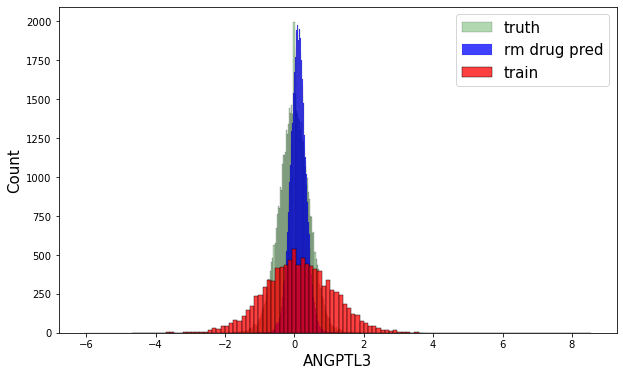

In [31]:
import matplotlib.pyplot as plt

prot = pd.read_pickle(PROT_FILE)

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.histplot(prot['ANGPTL3'], ax=ax, color='green', label='truth', alpha=0.3)
sns.histplot(df_nodrug['pred_res'], ax=ax, color='blue', label='rm drug pred')
# sns.histplot(test['pred_ANGPTL3'], ax=ax, color='orange', label='All pred', alpha=0.3)
sns.histplot(train['ANGPTL3'], ax=ax, color='red', label='train')
plt.legend(fontsize=15)
ax.set_xlabel('ANGPTL3', fontsize=15)
ax.set_ylabel('Count', fontsize=15)
ax.grid(False)

In [25]:
df_nodrug['pred_q'] = statistics.get_quartile(df_nodrug, 'pred_res')
df_nodrug = statistics.get_dummy(df_nodrug, 'pred_q')
df_nodrug.reset_index(drop=True, inplace=True)
res3 = statistics.surv_model(df_nodrug, ['survive_time', 'incident'], ['pred_q_1', 'pred_q_2', 'pred_q_3'], COVLIST, onehot_verbose=True)

0.0    72538
1.0     5038
Name: incident, dtype: int64
pred_q_1:{0.0: 18280, 1.0: 1114}
pred_q_2:{0.0: 18224, 1.0: 1170}
pred_q_3:{0.0: 18097, 1.0: 1297}


<lifelines.CoxPHFitter: fitted with 77576 total observations, 72538 right-censored observations>
             duration col = 'survive_time'
                event col = 'incident'
      baseline estimation = breslow
   number of observations = 77576
number of events observed = 5038
   partial log-likelihood = -55110.1601679142
         time fit was run = 2025-12-12 08:18:28 UTC

---
                   coef    exp(coef)     se(coef)   coef lower 95%   coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%
covariate                                                                                                                    
pred_q_1  -0.3456204580 0.7077810688 0.0398930164    -0.4238093333    -0.2674315827         0.6545486706         0.7653426915
pred_q_2  -0.2955862770 0.7440952137 0.0393319604    -0.3726755028    -0.2184970512         0.6888887391         0.8037258495
pred_q_3  -0.1628110983 0.8497516928 0.0382152549    -0.2377116216    -0.0879105750         0.7884300245         0.9158427723
sex        0.8618565902 2.3675521901 0.0292682203     0.8044919325     0.9192212479         2.2355603947         2.5073370356
age        0.0739565636 1.0767600339 0.0019827255     0.0700704930     0.0778426343         1.0725837882         1.0809525404
PC1       -0.0001843320 0.9998156850 0.0003544084    -0.0008789597     0.0005102956         0.9991214265         1.0005104258
PC2       -0.0011351082 0.9988655358 0.0006619927    -0.0024325900     0.0001623736         0.9975703664         1.0001623868
PC3        0.0064579993 1.0064788971 0.0011143710     0.0042738724     0.0086421262         1.0042830184         1.0086795772
PC4        0.0037222162 1.0037291522 0.0013925957     0.0009927788     0.0064516535         1.0009932718         1.0064725103
PC5        0.0061241444 1.0061429353 0.0018119294     0.0025728280     0.0096754607         1.0025761406         1.0097224193
PC6        0.0016617106 1.0016630920 0.0036673017    -0.0055260686     0.0088494899         0.9944891720         1.0088887624
PC7       -0.0015424463 0.9984587427 0.0029910968    -0.0074048882     0.0043199957         0.9926224605         1.0043293403
PC8        0.0051911043 1.0052046014 0.0032174699    -0.0011150209     0.0114972295         0.9988856005         1.0115635766
PC9        0.0093956535 1.0094399313 0.0032581222     0.0030098515     0.0157814556         1.0030143856         1.0159066405
PC10       0.0034088804 1.0034146972 0.0033204985    -0.0030991772     0.0099169379         0.9969056203         1.0099662737

                cmp to             z            p        -log2(p)
covariate                                                        
pred_q_1  0.0000000000 -8.6636832594       <5e-11   57.6032651581
pred_q_2  0.0000000000 -7.5151676670       <5e-11   44.0001364452
pred_q_3  0.0000000000 -4.2603692863 0.0000204089   15.5804391217
sex       0.0000000000 29.4468396455       <5e-11  630.6996878872
age       0.0000000000 37.3004542332       <5e-11 1009.1759397280
PC1       0.0000000000 -0.5201119585 0.6029855440    0.7298046797
PC2       0.0000000000 -1.7146839748 0.0864031832    3.5327717254
PC3       0.0000000000  5.7951970932 0.0000000068   27.1267142522
PC4       0.0000000000  2.6728620858 0.0075207162    7.0549142185
PC5       0.0000000000  3.3799023452 0.0007251159   10.4295007952
PC6       0.0000000000  0.4531153298 0.6504656973    0.6204551174
PC7       0.0000000000 -0.5156791595 0.6060785126    0.7224233995
PC8       0.0000000000  1.6134118955 0.1066550505    3.2289758111
PC9       0.0000000000  2.8837634384 0.0039295382    7.9914245089
PC10      0.0000000000  1.0266170386 0.3046008277    1.7150082326
---
Concordance = 0.6994205811
Partial AIC = 110250.3203358285
log-likelihood ratio test = 2521.2124046013 on 15 df
-log2(p) of ll-ratio test = inf

In [26]:
res3

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
pred_q_1,-0.345620,0.707781,0.039893,-0.423809,-0.267432,0.654549,0.765343,0.0,-8.663683,4.567613e-18,57.603265
pred_q_2,-0.295586,0.744095,0.039332,-0.372676,-0.218497,0.688889,0.803726,0.0,-7.515168,5.683804e-14,44.000136
pred_q_3,-0.162811,0.849752,0.038215,-0.237712,-0.087911,0.788430,0.915843,0.0,-4.260369,2.040894e-05,15.580439
sex,0.861857,2.367552,0.029268,0.804492,0.919221,2.235560,2.507337,0.0,29.446840,1.381897e-190,630.699688
age,0.073957,1.076760,0.001983,0.070070,0.077843,1.072584,1.080953,0.0,37.300454,1.613508e-304,1009.175940
PC1,-0.000184,0.999816,0.000354,-0.000879,0.000510,0.999121,1.000510,0.0,-0.520112,6.029855e-01,0.729805
PC2,-0.001135,0.998866,0.000662,-0.002433,0.000162,0.997570,1.000162,0.0,-1.714684,8.640318e-02,3.532772
PC3,0.006458,1.006479,0.001114,0.004274,0.008642,1.004283,1.008680,0.0,5.795197,6.824099e-09,27.126714
PC4,0.003722,1.003729,0.001393,0.000993,0.006452,1.000993,1.006473,0.0,2.672862,7.520716e-03,7.054914


In [27]:
df_nodrug.dropna().loc[df_nodrug['pred_q_4']==1,'incident'].value_counts()

0.0    17937
1.0     1457
Name: incident, dtype: int64

In [32]:
9511+78290

87801

In [33]:
1762+23639

25401

In [34]:
9511+78290

87801